# CustOmics on GS-BRCA with ANOVA F-test feature selection

**Why:** `01_brca_customics.ipynb` reached 0.842 accuracy / 0.792 macro-F1 on `GS-BRCA/Original`. The diagnosis:
671 patients against about 57 000 features (18 206 mRNA, 19 049 methylation, 19 568 CNV, 368 miRNA), so the signal is buried.
A logistic regression on only the 50 PAM50 genes already reaches 0.876 / 0.853.

**What this notebook does:** same data (`GS-BRCA/Original`), same folds and the same best model from notebook 01
(regularised 4-omics direct fusion). It adds one step: **ANOVA F-test feature selection inside every training fold**.

* The F-score of each feature against the PAM50 label is computed on the training patients of the fold only;
  validation and test patients never influence which features are kept (no leakage).
* The top-*k* features are kept **per omics**, so every omics still contributes; miRNA (368 features) is kept whole.
* Sweep: *k* = 500, 1000, 2000, 5000, plus no selection (the notebook-01 result) as the reference point.
* A logistic regression with the same selection is run at every *k* as a classical baseline.

The best *k* is chosen by mean macro-F1 over the 5 test folds and saved to `results/brca_anova/`.

In [1]:
import os, copy, json, random, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report, confusion_matrix,
                             f1_score, normalized_mutual_info_score, precision_score, recall_score,
                             roc_auc_score, silhouette_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
N_FOLDS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "data/MLOmics/Main_Dataset/Classification_datasets/GS-BRCA/Original"
RESULTS_DIR = "results/brca_anova"
os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load data (GS-BRCA Original)

In [2]:
OMICS = ["mRNA", "Methy", "CNV", "miRNA"]

X_all = {}
for m in OMICS:
    df = pd.read_csv(os.path.join(DATA_DIR, f"BRCA_{m}.csv"), index_col=0).T      # -> patients x features
    X_all[m] = df.dropna(axis=1, how="all")                                        # drop features never measured
y = pd.read_csv(os.path.join(DATA_DIR, "BRCA_label_num.csv"))["Label"].to_numpy()

patients = X_all["mRNA"].index
assert all(X_all[m].index.equals(patients) for m in OMICS) and len(y) == len(patients)
N_CLASSES = len(np.unique(y))

print(f"{len(patients)} patients, {N_CLASSES} PAM50 subtypes\n")
print(pd.DataFrame({m: [X_all[m].shape[1], int(X_all[m].isna().sum().sum())] for m in OMICS},
                   index=["features", "missing values"]))
print("\nPatients per class:", pd.Series(y).value_counts().sort_index().to_dict())

671 patients, 5 PAM50 subtypes

                 mRNA  Methy    CNV  miRNA
features        18206  19049  19568    368
missing values      0      0      0      0

Patients per class: {0: 353, 1: 42, 2: 132, 3: 31, 4: 113}


## 2. Model: CustOmics mixed integration

* **Phase 1 – per-omics autoencoders.** Each omics source has its own encoder/decoder
  (`Linear → BatchNorm → ReLU → Dropout → Linear → BatchNorm → ReLU`) that compresses it to a 64-D sub-latent.
  As in the CustOmics paper, each source also gets a small auxiliary classifier head in this phase, so the sub-latent
  is pushed to hold subtype signal, not only reconstructable variance.
* **Phase 2 – fusion + classification.** The sub-latents are fused and fed to the classifier; everything is fine-tuned
  end-to-end with `reconstruction + 2 × cross-entropy`.
  * `fusion="direct"`: concatenate the sub-latents (4 × 64 = 256-D) → classifier. This was the **best model in
    `reference_material`** (`custOmics2.ipynb`, pan-cancer acc 0.9725 / macro-F1 0.9640).
  * `fusion="vae"`: concatenate → central VAE with MMD regularisation → classifier on μ (the original CustOmics design,
    `customics_pancancer1.ipynb`, acc 0.9667 / macro-F1 0.9427).
* Cross-entropy is **class-weighted** (inverse class frequency), the imbalance fix proposed in the synopsis.

In [3]:
class SourceAE(nn.Module):
    """Per-omics autoencoder: compresses one omics source to a small latent vector."""
    def __init__(self, in_dim, latent_dim, hidden=256, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, latent_dim), nn.BatchNorm1d(latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),
            nn.Linear(hidden, in_dim))


class CustOmics(nn.Module):
    """Per-omics autoencoders -> fusion ("direct" concat or central "vae") -> classifier."""
    def __init__(self, in_dims, n_classes, latent_dim=64, fusion="direct", central_dim=64, hidden=256, dropout=0.2):
        super().__init__()
        self.omics, self.fusion = list(in_dims), fusion
        self.aes = nn.ModuleDict({m: SourceAE(d, latent_dim, hidden, dropout) for m, d in in_dims.items()})
        self.aux_heads = nn.ModuleDict({m: nn.Linear(latent_dim, n_classes) for m in in_dims})  # phase 1 only
        fused_dim = latent_dim * len(in_dims)
        if fusion == "vae":
            self.central_enc = nn.Sequential(nn.Linear(fused_dim, 128), nn.BatchNorm1d(128), nn.ReLU())
            self.fc_mu, self.fc_logvar = nn.Linear(128, central_dim), nn.Linear(128, central_dim)
            self.central_dec = nn.Sequential(nn.Linear(central_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                             nn.Linear(128, fused_dim))
            fused_dim = central_dim
        self.classifier = nn.Sequential(nn.Linear(fused_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(128, n_classes))

    def encode(self, xs):
        return {m: self.aes[m].encoder(xs[m]) for m in self.omics}

    def forward(self, xs):
        z = self.encode(xs)
        out = {"recon": {m: self.aes[m].decoder(z[m]) for m in self.omics}}
        h = torch.cat([z[m] for m in self.omics], dim=1)
        if self.fusion == "vae":
            e = self.central_enc(h)
            mu, logvar = self.fc_mu(e), self.fc_logvar(e)
            zc = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
            out.update(h=h, h_hat=self.central_dec(zc), zc=zc)
            h = mu
        out["latent"], out["logits"] = h, self.classifier(h)
        return out


def mmd(z):
    """MMD between z and samples of N(0, I), RBF kernel with bandwidth = latent dim."""
    prior = torch.randn_like(z)
    k = lambda a, b: torch.exp(-torch.cdist(a, b).pow(2) / z.shape[1])
    return k(z, z).mean() + k(prior, prior).mean() - 2 * k(z, prior).mean()

## 3. Training and evaluation

* **Stratified 5-fold CV.** Inside every training fold, 15 % is held out (stratified) as a validation set used only
  for early stopping. The test fold is never touched during training or model selection.
* **Preprocessing** (median imputation + standardisation per omics) is fitted on the training patients of each fold only.
* The best epoch is chosen by the lowest validation cross-entropy, and a real copy of its weights is restored
  (`copy.deepcopy`). The reference notebooks used `state_dict().copy()`, which is a shallow copy and silently
  keeps the *last* weights.
* Metrics on each test fold: accuracy, macro precision / recall / F1, ROC-AUC (one-vs-rest), NMI and ARI.
* **New:** `fit_preprocessors` now runs `SimpleImputer → SelectKBest(f_classif, k) → StandardScaler` per omics,
  fitted on the training patients of the fold. The fitted selector is saved with each model, so a saved model knows
  which genes it uses.

In [4]:
CFG = dict(omics=OMICS, latent_dim=64, fusion="direct", hidden=256, dropout=0.2, lr=1e-3, weight_decay=1e-4,
           batch_size=64, p1_epochs=50, p2_epochs=150, min_epochs=30, patience=20, ce_weight=2.0, mmd_weight=1.0)
METRICS = ["accuracy", "precision", "recall", "f1_macro", "roc_auc", "nmi", "ari"]
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))


def fit_preprocessors(idx, omics, top_k=None):
    """Per omics: median-impute -> keep the top_k features by ANOVA F-test -> standardise.
    Fitted on the given (training) patients only, so test patients never influence which features are kept."""
    pipes = {}
    for m in omics:
        k = "all" if top_k is None or X_all[m].shape[1] <= top_k else top_k
        pipes[m] = make_pipeline(SimpleImputer(strategy="median"), SelectKBest(f_classif, k=k), StandardScaler())
        pipes[m].fit(X_all[m].iloc[idx], y[idx])
    return pipes


def to_tensors(idx, pipes):
    return {m: torch.tensor(p.transform(X_all[m].iloc[idx]), dtype=torch.float32, device=DEVICE)
            for m, p in pipes.items()}


def minibatches(n, batch_size):
    idx = torch.randperm(n, device=DEVICE)
    return [b for b in idx.split(batch_size) if len(b) > 1]  # BatchNorm needs > 1 sample


@torch.no_grad()
def predict(model, xs, batch_size=1024):
    model.eval()
    n = len(next(iter(xs.values())))
    probs, latents = [], []
    for s in range(0, n, batch_size):
        out = model({m: x[s:s + batch_size] for m, x in xs.items()})
        probs.append(F.softmax(out["logits"], dim=1).cpu())
        latents.append(out["latent"].cpu())
    return torch.cat(probs).numpy(), torch.cat(latents).numpy()


def train_model(xs_tr, y_tr, xs_va, y_va, cfg, class_weights):
    omics = cfg["omics"]
    model = CustOmics({m: xs_tr[m].shape[1] for m in omics}, N_CLASSES, cfg["latent_dim"], cfg["fusion"],
                      hidden=cfg["hidden"], dropout=cfg["dropout"]).to(DEVICE)
    ce = nn.CrossEntropyLoss(weight=class_weights)
    n = len(y_tr)

    # Phase 1: each omics autoencoder learns to reconstruct its source and predict the label
    opt = torch.optim.Adam([*model.aes.parameters(), *model.aux_heads.parameters()],
                           lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    for _ in range(cfg["p1_epochs"]):
        model.train()
        for b in minibatches(n, cfg["batch_size"]):
            z = model.encode({m: xs_tr[m][b] for m in omics})
            loss = sum(F.mse_loss(model.aes[m].decoder(z[m]), xs_tr[m][b]) + ce(model.aux_heads[m](z[m]), y_tr[b])
                       for m in omics)
            opt.zero_grad(); loss.backward(); opt.step()

    # Phase 2: fuse the sub-latents and fine-tune everything end-to-end
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    best = {"loss": float("inf"), "epoch": 0, "state": None}
    for epoch in range(1, cfg["p2_epochs"] + 1):
        model.train()
        for b in minibatches(n, cfg["batch_size"]):
            xb = {m: xs_tr[m][b] for m in omics}
            out = model(xb)
            loss = sum(F.mse_loss(out["recon"][m], xb[m]) for m in omics) + cfg["ce_weight"] * ce(out["logits"], y_tr[b])
            if cfg["fusion"] == "vae":
                loss = loss + F.mse_loss(out["h_hat"], out["h"].detach()) + cfg["mmd_weight"] * mmd(out["zc"])
            opt.zero_grad(); loss.backward(); opt.step()

        # early stopping on the inner validation split
        model.eval()
        with torch.no_grad():
            val_loss = ce(model(xs_va)["logits"], y_va).item()
        if val_loss < best["loss"] - 1e-4:
            best = {"loss": val_loss, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        elif epoch >= cfg["min_epochs"] and epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"])
    return model, best["epoch"]


def scores(y_true, proba):
    y_pred = proba.argmax(1)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro"),
            "roc_auc": roc_auc_score(y_true, proba, multi_class="ovr", labels=np.arange(N_CLASSES)),
            "nmi": normalized_mutual_info_score(y_true, y_pred),
            "ari": adjusted_rand_score(y_true, y_pred)}


def run_cv(name, cfg):
    """Stratified 5-fold CV; returns per-fold metrics, out-of-fold predictions/latents and the trained models."""
    rows, models, oof_proba, oof_latent = [], [], np.zeros((len(y), N_CLASSES)), None
    t0 = time.time()
    for fold, (train_idx, test_idx) in enumerate(FOLDS, 1):
        set_seed(SEED + fold)
        fit_idx, val_idx = train_test_split(train_idx, test_size=0.15, stratify=y[train_idx], random_state=SEED)
        pipes = fit_preprocessors(fit_idx, cfg["omics"], cfg.get("top_k"))
        xs_fit, xs_val, xs_test = (to_tensors(i, pipes) for i in (fit_idx, val_idx, test_idx))
        y_fit, y_val = (torch.tensor(y[i], device=DEVICE) for i in (fit_idx, val_idx))
        counts = np.bincount(y[fit_idx], minlength=N_CLASSES)
        class_weights = torch.tensor(len(fit_idx) / (N_CLASSES * counts), dtype=torch.float32, device=DEVICE)

        model, best_epoch = train_model(xs_fit, y_fit, xs_val, y_val, cfg, class_weights)
        proba, latent = predict(model, xs_test)
        oof_proba[test_idx] = proba
        if oof_latent is None:
            oof_latent = np.zeros((len(y), latent.shape[1]), dtype=np.float32)
        oof_latent[test_idx] = latent
        rows.append({"fold": fold, **scores(y[test_idx], proba), "best_epoch": best_epoch})
        models.append({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "preprocess": pipes,
                       "in_dims": {m: xs_fit[m].shape[1] for m in cfg["omics"]}})
        print(f"[{name}] fold {fold}: acc={rows[-1]['accuracy']:.4f}  macro-F1={rows[-1]['f1_macro']:.4f}  "
              f"best epoch={best_epoch}")
    print(f"[{name}] finished in {time.time() - t0:.0f}s\n")
    return {"name": name, "cfg": cfg, "folds": pd.DataFrame(rows), "oof_proba": oof_proba,
            "oof_latent": oof_latent, "models": models}


def summary_table(runs):
    """mean ± std over the 5 test folds for every run."""
    return pd.DataFrame({r["name"]: {k: f"{r['folds'][k].mean():.4f} ± {r['folds'][k].std():.4f}" for k in METRICS}
                         for r in runs}).T


def save_run(run, out_dir, class_names=None):
    """Save fold models, preprocessing, metrics and out-of-fold predictions of one run."""
    os.makedirs(os.path.join(out_dir, "models"), exist_ok=True)
    for fold, m in enumerate(run["models"], 1):
        torch.save({"state_dict": m["state_dict"], "in_dims": m["in_dims"], "n_classes": N_CLASSES, "config": run["cfg"]},
                   os.path.join(out_dir, "models", f"fold_{fold}.pt"))
        joblib.dump(m["preprocess"], os.path.join(out_dir, "models", f"preprocess_fold_{fold}.joblib"))
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump({"name": run["name"], **run["cfg"], "seed": SEED, "n_folds": N_FOLDS}, f, indent=2)

    run["folds"].to_csv(os.path.join(out_dir, "cv_metrics_per_fold.csv"), index=False)
    summary = run["folds"][METRICS].agg(["mean", "std"]).T
    summary.to_csv(os.path.join(out_dir, "cv_metrics_summary.csv"))

    y_pred = run["oof_proba"].argmax(1)
    preds = pd.DataFrame(run["oof_proba"], index=patients, columns=[f"p_class_{c}" for c in range(N_CLASSES)])
    preds.insert(0, "y_pred", y_pred); preds.insert(0, "y_true", y)
    preds.to_csv(os.path.join(out_dir, "oof_predictions.csv"), index_label="patient")
    np.save(os.path.join(out_dir, "oof_latent.npy"), run["oof_latent"])

    report = pd.DataFrame(classification_report(y, y_pred, target_names=class_names, output_dict=True,
                                                zero_division=0)).T
    report.to_csv(os.path.join(out_dir, "per_class_metrics.csv"))
    return summary, report

## 4. k-sweep

All runs use the same 5 folds and the same model settings as the notebook-01 winner; only *k* changes.

In [5]:
REG = dict(dropout=0.5, weight_decay=1e-3, hidden=128, p1_epochs=20)
BEST_01 = dict(CFG, **REG)            # winner of 01_brca_customics.ipynb (4 omics, direct fusion, regularised)
K_VALUES = [500, 1000, 2000, 5000]


def run_logreg(top_k):
    name = f"LogReg | ANOVA top-{top_k}" if top_k else "LogReg | no selection"
    rows = []
    for fold, (train_idx, test_idx) in enumerate(FOLDS, 1):
        pipes = fit_preprocessors(train_idx, OMICS, top_k)
        X_tr = np.hstack([pipes[m].transform(X_all[m].iloc[train_idx]) for m in OMICS])
        X_te = np.hstack([pipes[m].transform(X_all[m].iloc[test_idx]) for m in OMICS])
        clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X_tr, y[train_idx])
        rows.append({"fold": fold, **scores(y[test_idx], clf.predict_proba(X_te))})
    print(f"[{name}] done")
    return {"name": name, "top_k": top_k, "folds": pd.DataFrame(rows)}


runs = [run_cv("CustOmics | no selection (notebook 01)", BEST_01)]
runs += [run_cv(f"CustOmics | ANOVA top-{k}", dict(BEST_01, top_k=k)) for k in K_VALUES]
lr_runs = [run_logreg(None)] + [run_logreg(k) for k in K_VALUES]

[CustOmics | no selection (notebook 01)] fold 1: acc=0.8444  macro-F1=0.8012  best epoch=4


[CustOmics | no selection (notebook 01)] fold 2: acc=0.7761  macro-F1=0.7407  best epoch=4


[CustOmics | no selection (notebook 01)] fold 3: acc=0.8358  macro-F1=0.7450  best epoch=19


[CustOmics | no selection (notebook 01)] fold 4: acc=0.8731  macro-F1=0.8302  best epoch=35


[CustOmics | no selection (notebook 01)] fold 5: acc=0.8806  macro-F1=0.8421  best epoch=9
[CustOmics | no selection (notebook 01)] finished in 46s



...

[LogReg | no selection] done


[LogReg | ANOVA top-500] done


[LogReg | ANOVA top-1000] done


[LogReg | ANOVA top-2000] done


[LogReg | ANOVA top-5000] done


,accuracy,precision,recall,f1_macro,roc_auc,nmi,ari
CustOmics | no selection (notebook 01),0.8420 ± 0.0414,0.7879 ± 0.0630,0.8103 ± 0.0329,0.7918 ± 0.0471,0.9576 ± 0.0224,0.6481 ± 0.0388,0.6454 ± 0.0857
CustOmics | ANOVA top-500,0.8599 ± 0.0413,0.8081 ± 0.0577,0.8540 ± 0.0378,0.8234 ± 0.0490,0.9685 ± 0.0217,0.6895 ± 0.0557,0.6767 ± 0.0925
CustOmics | ANOVA top-1000,0.8510 ± 0.0203,0.8038 ± 0.0451,0.8416 ± 0.0463,0.8178 ± 0.0427,0.9720 ± 0.0137,0.6692 ± 0.0374,0.6524 ± 0.0573
CustOmics | ANOVA top-2000,0.8390 ± 0.0337,0.7906 ± 0.0281,0.8475 ± 0.0510,0.8086 ± 0.0392,0.9703 ± 0.0152,0.6506 ± 0.0433,0.6248 ± 0.0713
CustOmics | ANOVA top-5000,0.8331 ± 0.0264,0.7827 ± 0.0414,0.7867 ± 0.0586,0.7748 ± 0.0452,0.9651 ± 0.0188,0.6289 ± 0.0579,0.6254 ± 0.0532
LogReg | no selection,0.8390 ± 0.0336,0.7778 ± 0.0586,0.7618 ± 0.0574,0.7621 ± 0.0549,0.9596 ± 0.0139,0.6364 ± 0.0601,0.6510 ± 0.0677
LogReg | ANOVA top-500,0.8599 ± 0.0228,0.8432 ± 0.0558,0.8017 ± 0.0674,0.8124 ± 0.0540,0.9757 ± 0.0073,0.6725 ± 0.0464,0.6687 ± 0.0250
LogReg | ANOVA top-1000,0.8569 ± 0.0188,0.8268 ± 0.0435,0.8118 ± 0.0505,0.8163 ± 0.0460,0.9750 ± 0.0076,0.6657 ± 0.0446,0.6599 ± 0.0234
LogReg | ANOVA top-2000,0.8555 ± 0.0423,0.7916 ± 0.1013,0.7854 ± 0.0818,0.7858 ± 0.0915,0.9728 ± 0.0097,0.6665 ± 0.0811,0.6768 ± 0.0803
LogReg | ANOVA top-5000,0.8450 ± 0.0306,0.8043 ± 0.0833,0.7814 ± 0.0754,0.7878 ± 0.0765,0.9676 ± 0.0130,0.6533 ± 0.0644,0.6493 ± 0.0477


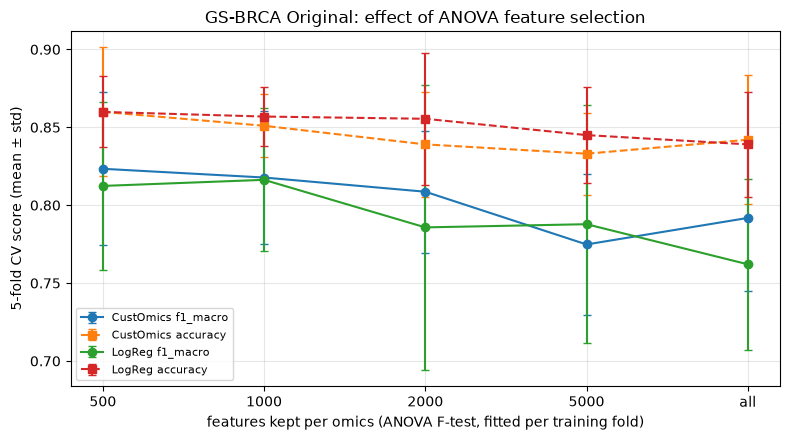

In [6]:
comparison = summary_table(runs + lr_runs)
comparison.to_csv(os.path.join(RESULTS_DIR, "k_sweep_comparison.csv"))
display(comparison)

# k-sweep plot (x = features kept per omics; "all" = no selection)
labels = [str(k) for k in K_VALUES] + ["all"]
order = lambda rs: rs[1:] + rs[:1]   # put "no selection" last
fig, ax = plt.subplots(figsize=(8, 4.5))
for rs, model in [(order(runs), "CustOmics"), (order(lr_runs), "LogReg")]:
    for metric, style in [("f1_macro", "-o"), ("accuracy", "--s")]:
        mean = [r["folds"][metric].mean() for r in rs]
        std = [r["folds"][metric].std() for r in rs]
        ax.errorbar(labels, mean, yerr=std, fmt=style, capsize=3, label=f"{model} {metric}")
ax.set_xlabel("features kept per omics (ANOVA F-test, fitted per training fold)")
ax.set_ylabel("5-fold CV score (mean ± std)")
ax.set_title("GS-BRCA Original: effect of ANOVA feature selection")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "k_sweep.png"), dpi=200); plt.show()

## 5. Best model: save and analyse

The best CustOmics run (highest mean macro-F1) is saved to `results/brca_anova/`: 5 fold models with their fitted
preprocessing + feature selector, metrics, out-of-fold predictions and latent vectors.

In [7]:
best = max(runs, key=lambda r: r["folds"]["f1_macro"].mean())
print("Best model:", best["name"])

summary, per_class = save_run(best, RESULTS_DIR)
display(best["folds"].round(4))
print("\nMean ± std over 5 folds")
display(summary.round(4))
print("\nPer-class metrics (pooled out-of-fold predictions)")
display(per_class.round(3))

Best model: CustOmics | ANOVA top-500


,fold,accuracy,precision,recall,f1_macro,roc_auc,nmi,ari,best_epoch
0,1,0.8593,0.8155,0.8955,0.8441,0.9826,0.6680,0.6519,12
1,2,0.7985,0.7090,0.8086,0.7414,0.9653,0.6260,0.5686,9
2,3,0.9104,0.8341,0.8493,0.8376,0.9321,0.7691,0.8217,28
3,4,0.8806,0.8586,0.8890,0.8707,0.9851,0.7201,0.6907,18
4,5,0.8507,0.8231,0.8277,0.8230,0.9773,0.6641,0.6507,21



Mean ± std over 5 folds


,mean,std
accuracy,0.8599,0.0413
precision,0.8081,0.0577
recall,0.8540,0.0378
f1_macro,0.8234,0.0490
roc_auc,0.9685,0.0217
nmi,0.6895,0.0557
ari,0.6767,0.0925



Per-class metrics (pooled out-of-fold predictions)


,precision,recall,f1-score,support
0,0.929,0.853,0.889,353.00
1,0.809,0.905,0.854,42.00
2,0.738,0.811,0.773,132.00
3,0.548,0.742,0.630,31.00
4,0.956,0.956,0.956,113.00
accuracy,0.860,0.860,0.860,0.86
macro avg,0.796,0.853,0.820,671.00
weighted avg,0.871,0.860,0.863,671.00


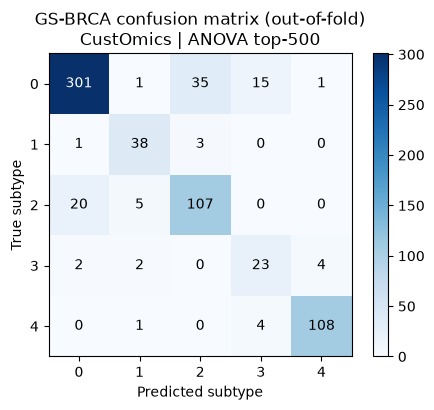

In [8]:
y_pred = best["oof_proba"].argmax(1)
cm = confusion_matrix(y, y_pred)

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xlabel("Predicted subtype"); ax.set_ylabel("True subtype")
ax.set_title(f"GS-BRCA confusion matrix (out-of-fold)\n{best['name']}")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=200); plt.show()

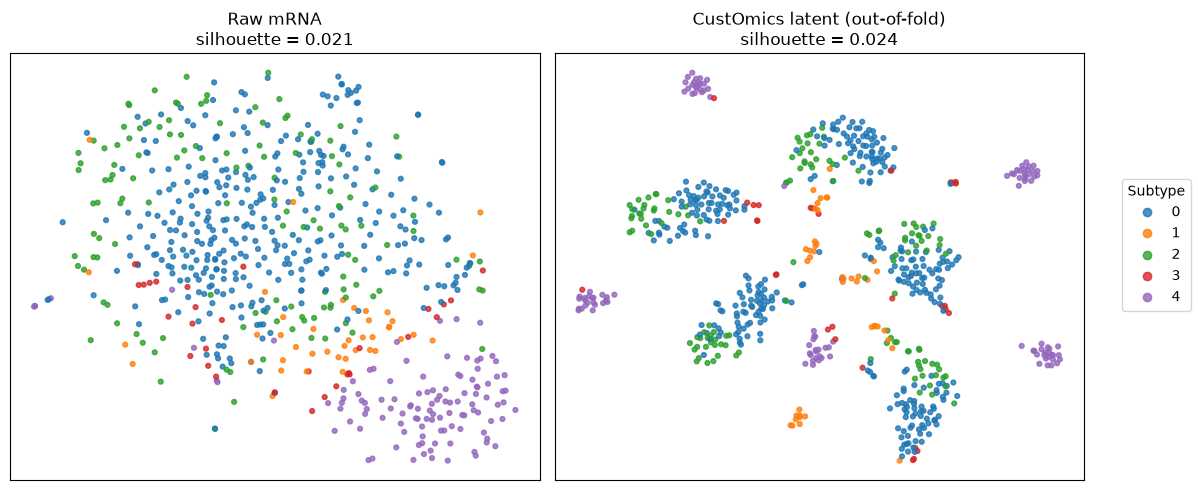

In [9]:
# Latent space: every patient is embedded by the fold model that never saw it during training
raw_mrna = StandardScaler().fit_transform(X_all["mRNA"])
embeddings = {"Raw mRNA": raw_mrna, "CustOmics latent (out-of-fold)": best["oof_latent"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, emb) in zip(axes, embeddings.items()):
    xy = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(emb)
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=12, alpha=0.8)
    ax.set_title(f"{title}\nsilhouette = {silhouette_score(emb, y):.3f}")
    ax.set_xticks([]); ax.set_yticks([])
fig.legend(*sc.legend_elements(), title="Subtype", loc="center right")
plt.tight_layout(rect=(0, 0, 0.92, 1))
plt.savefig(os.path.join(RESULTS_DIR, "latent_tsne.png"), dpi=200); plt.show()

## 6. Which features were selected?

Selection is refitted in every fold, so we check how stable it is (overlap of the selected sets across folds) and list the
features with the highest mean F-score. For mRNA we also check how many of the 50 PAM50 genes were picked up.

In [10]:
PAM50 = set("""ACTR3B ANLN BAG1 BCL2 BIRC5 BLVRA CCNB1 CCNE1 CDC20 CDC6 CDH3 CENPF CEP55 CXXC5 EGFR ERBB2 ESR1 EXO1
FGFR4 FOXA1 FOXC1 GPR160 GRB7 KIF2C KRT14 KRT17 KRT5 MAPT MDM2 MELK MIA MKI67 MLPH MMP11 MYBL2 MYC NAT1 NDC80
NUF2 ORC6 PGR PHGDH PTTG1 RRM2 SFRP1 SLC39A6 TMEM45B TYMS UBE2C UBE2T""".split())

stability, top_features = [], {}
for m in best["cfg"]["omics"]:
    selectors = [mod["preprocess"][m].named_steps["selectkbest"] for mod in best["models"]]
    sets = [set(X_all[m].columns[s.get_support()]) for s in selectors]
    pairs = [len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i + 1:]]
    stability.append({"omics": m, "features kept": len(sets[0]), "kept in all 5 folds": len(set.intersection(*sets)),
                      "mean pairwise Jaccard": round(float(np.mean(pairs)), 3)})
    table = pd.DataFrame({"feature": X_all[m].columns,
                          "mean_F": np.mean([s.scores_ for s in selectors], axis=0),
                          "folds_selected": np.sum([s.get_support() for s in selectors], axis=0)})
    table = table[table.folds_selected > 0].sort_values("mean_F", ascending=False).reset_index(drop=True)
    table.to_csv(os.path.join(RESULTS_DIR, f"selected_features_{m}.csv"), index=False)
    top_features[m] = table

print("Selection stability across the 5 folds")
display(pd.DataFrame(stability))
mrna_sel = set(top_features["mRNA"].feature[top_features["mRNA"].folds_selected == N_FOLDS])
print(f"PAM50 genes kept in all 5 folds: {len(PAM50 & mrna_sel)}/50 -> {sorted(PAM50 & mrna_sel)}")
print("\nTop 15 features per omics (mean F-score over folds)")
display(pd.concat({m: t.head(15)[["feature", "mean_F"]].reset_index(drop=True) for m, t in top_features.items()}, axis=1))

Selection stability across the 5 folds


,omics,features kept,kept in all 5 folds,mean pairwise Jaccard
0,mRNA,500,382,0.773
1,Methy,500,384,0.785
2,CNV,500,309,0.629
3,miRNA,368,368,1.000


PAM50 genes kept in all 5 folds: 32/50 -> ['ANLN', 'BCL2', 'BIRC5', 'CCNB1', 'CCNE1', 'CDC20', 'CENPF', 'CEP55', 'CXXC5', 'EGFR', 'ESR1', 'EXO1', 'FOXA1', 'FOXC1', 'GPR160', 'KIF2C', 'MAPT', 'MELK', 'MIA', 'MKI67', 'MLPH', 'MYBL2', 'NAT1', 'NDC80', 'NUF2', 'ORC6', 'PGR', 'PHGDH', 'PTTG1', 'SFRP1', 'SLC39A6', 'UBE2C']

Top 15 features per omics (mean F-score over folds)


mRNA                 Methy                   CNV             \
    feature      mean_F   feature      mean_F   feature     mean_F   
0     FOXA1  494.057253       MIA  192.938621      SPZ1  54.719925   
1      MLPH  373.883673    CHI3L1  182.467328    HOMER1  54.265893   
2     FOXC1  313.127168      DNM3  178.386744  TMEM161B  54.175144   
3      ESR1  290.756954  HIST1H1A  164.971994     CMYA5  53.888082   
4     SPDEF  273.531020    ITPRIP  155.713363   ZFYVE16  53.840354   
5     GATA3  244.589511     ARL4C  144.840880      MTX3  53.628053   
6    TBC1D9  214.409753    KRTDAP  139.424573     PAPD4  53.382918   
7      CA12  212.363009   A3GALT2  122.195771     THBS4  53.175334   
8    BCL11A  194.397465      TFF1  120.794624       JMY  52.914909   
9      AGR2  193.641575     TAGLN  119.600308    LYSMD3  52.831016   
10  SLC44A4  192.606751      AGR3  119.039420     MEF2C  52.809494   
11     AGR3  191.833028     MFAP2  116.560172    POLR3G  52.444303   
12   SRSF12  190.455409   SLC43A3  115.783975    MBLAC2  52.279849   
13    PSAT1  188.487314     TMCC1  114.303692     COX7C  52.187175   
14    PRR15  178.639469    ZNF609  113.972332     CETN3  52.141391   

            miRNA              
          feature      mean_F  
0     hsa.mir.18a  144.099423  
1      hsa.mir.17  101.230503  
2     hsa.mir.505   96.024951  
3    hsa.mir.135b   93.866288  
4     hsa.mir.19a   88.539705  
5    hsa.mir.130b   80.422489  
6     hsa.mir.20a   76.517114  
7     hsa.mir.188   75.335597  
8    hsa.mir.106b   74.886668  
9    hsa.mir.190b   68.946408  
10   hsa.mir.1307   67.672424  
11    hsa.mir.455   64.818386  
12    hsa.mir.590   63.686801  
13  hsa.mir.92a.1   63.370273  
14    hsa.mir.942   62.847619

## 7. Conclusions

| GS-BRCA Original, 5-fold CV | Accuracy | Macro-F1 | ROC-AUC |
|---|---|---|---|
| CustOmics, no selection (notebook 01) | 0.842 ± 0.041 | 0.792 ± 0.047 | 0.958 |
| **CustOmics, ANOVA top-500 per omics** | **0.860 ± 0.041** | **0.823 ± 0.049** | 0.969 |
| CustOmics, ANOVA top-1000 | 0.851 ± 0.020 | 0.818 ± 0.043 | 0.972 |
| LogReg, ANOVA top-500 | 0.860 ± 0.023 | 0.812 ± 0.054 | 0.976 |

* **In-fold ANOVA selection helps**: +1.8 accuracy points and +3.2 macro-F1 points over using all ~57k features.
  Smaller *k* is better (500 > 1000 > 2000 > 5000 > all), which confirms the diagnosis: too many features for 671 patients.
* The gain is mostly on **recall of the hard classes**: macro-recall 0.810 → 0.854; HER2-enriched (class 1) F1 0.74 → 0.85,
  LumB (class 2) F1 0.74 → 0.77. Normal-like (class 3, n = 31) remains the hardest class (F1 0.63).
* CustOmics matches LogReg on accuracy (0.860 both) and is better on macro-F1 (0.823 vs 0.812) and macro-recall (0.854 vs 0.802),
  so it is more balanced across subtypes; LogReg remains slightly better on ROC-AUC.
* The selection is stable and biologically sensible: 77 % average overlap of mRNA genes between folds; 32 of the 50 PAM50 genes are
  picked in every fold, and the top genes (FOXA1, ESR1, FOXC1, GATA3, MLPH, SPDEF, AGR2/3) are the textbook luminal-vs-basal markers.
  CNV is the least stable omics (Jaccard 0.63), consistent with it carrying the weakest subtype signal.
* Fold-to-fold variation (± 4 %) is still large; fold 2 is consistently the hardest split for every model.

**Saved in `results/brca_anova/`:** the 5 fold models with fitted selectors (`models/`), metrics, k-sweep table and plot,
out-of-fold predictions, confusion matrix, t-SNE, and the selected-feature lists per omics.
